In [1]:
from pipeline import PipelineEDA

## 1. Cargar

In [2]:
pipeline = PipelineEDA("data/online_retail.csv")
pipeline.df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 2. Análisis inicial

In [3]:
pipeline.analizar()

ARCHIVO: online_retail.csv

INFORMACION GENERAL DEL DATASET:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


            Quantity      UnitPrice     CustomerID
count  541909.000000  541909.000000  406829.000000
mean        9.552250       4.611114   15287.690570
std       218.081158      96.759853    1713.600303
min    -80995.000000  -11062.060000   12346.000000
25%         1.000000       1.250000   13953.000000
50%         3.000000       2

## 3. Nulos

In [4]:
pipeline.tratar_nulos(["CustomerID"])

Se eliminaron los nulos de: CustomerID


In [5]:
pipeline.ver_nulos()


ANALISIS DE VALORES NULOS

TABLA DE VALORES NULOS:
             Cantidad de nulos  Porcentaje de nulos
InvoiceNo                    0                  0.0
StockCode                    0                  0.0
Description                  0                  0.0
Quantity                     0                  0.0
InvoiceDate                  0                  0.0
UnitPrice                    0                  0.0
CustomerID                   0                  0.0
Country                      0                  0.0

TOTAL DE VALORES NULOS:
0


## 4. Duplicados

In [6]:
pipeline.ver_duplicados()

Filas duplicadas: 5,225


In [7]:
pipeline.eliminar_duplicados()

Filas eliminadas: 5,225
Filas restantes: 401,604


## 5. Facturas canceladas

In [8]:
pipeline.filtrar_facturas_canceladas(obtener=True).head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


In [9]:
pipeline.filtrar_facturas_canceladas()


Se eliminaron las facturas canceladas.


## 6. Cantidades y precios inválidos

In [10]:
pipeline.filtrar_ventas_positivas()

Filas eliminadas: 40
Filas restantes: 392,692


## 7. Códigos que no son productos

In [11]:
no_productos = ["POST", "DOT", "M", "D", "C2", "S", "BANK CHARGES", "AMAZONFEE", "CRUK", "PADS"]

In [12]:
pipeline.filtrar_codigos_no_producto(no_productos, obtener=True)['Description'].value_counts()

Description
POSTAGE                       1099
Manual                         279
CARRIAGE                       133
DOTCOM POSTAGE                  16
Bank Charges                    12
PADS TO MATCH ALL CUSHIONS       3
Name: count, dtype: int64

In [13]:
pipeline.filtrar_codigos_no_producto(no_productos)

Filas eliminadas: 1,542
Filas restantes: 391,150


## 8. Descripciones

In [14]:
pipeline.limpiar_descripciones()

Filas corregidas: 94,033


## 9. Tipos de datos

In [15]:
pipeline.convertir_tipos(columnas_int=["CustomerID"], columnas_fecha=["InvoiceDate"])

InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID              Int64
Country                object
dtype: object


## 10. Outliers

In [16]:
pipeline.df[["Quantity", "UnitPrice"]].describe()

,Quantity,UnitPrice
count,391150.000000,391150.000000
mean,13.145300,2.874372
std,180.807831,4.284738
min,1.000000,0.040000
25%,2.000000,1.250000
50%,6.000000,1.950000
75%,12.000000,3.750000
max,80995.000000,649.500000


In [17]:
pipeline.eliminar_outliers(["Quantity", "UnitPrice"])

Quantity: limite = 120.00
UnitPrice: limite = 12.75
Filas eliminadas: 7,384
Filas restantes: 383,766


In [18]:
pipeline.df[["Quantity", "UnitPrice"]].describe()

,Quantity,UnitPrice
count,383766.000000,383766.000000
mean,10.030761,2.696806
std,14.657576,2.464347
min,1.000000,0.040000
25%,2.000000,1.250000
50%,6.000000,1.850000
75%,12.000000,3.750000
max,120.000000,12.750000


## 11. Columnas nuevas

In [19]:
pipeline.crear_columnas()

Columnas nuevas: Total, Mes, Dia, Hora


In [20]:
pipeline.df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Total,Mes,Dia,Hora
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,2010-12,Wednesday,8
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,Wednesday,8
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,2010-12,Wednesday,8
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,Wednesday,8
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,Wednesday,8


## 12. Resultado

In [21]:
pipeline.resumen_limpieza()

RESUMEN DE LIMPIEZA
Filas iniciales: 541,909
Filas finales: 383,766
Eliminadas: 158,143 (29.2%)
Nulos restantes: 0
Duplicados restantes: 0


In [22]:
pipeline.guardar("online_retail_limpio.csv")

Guardado en: online_retail_limpio.csv


### EDA

RESUMEN GENERAL
Facturas : 17,951
Clientes : 4,289
Productos: 3,610
Países   : 37
Ventas   : 6,846,370.96


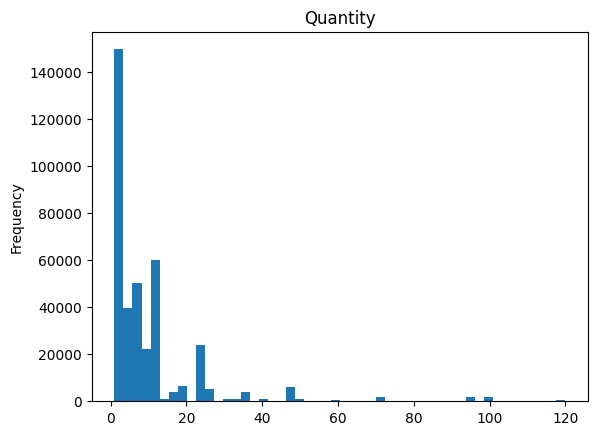

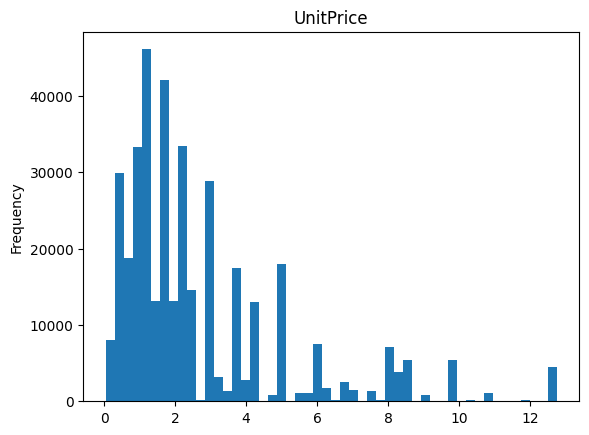

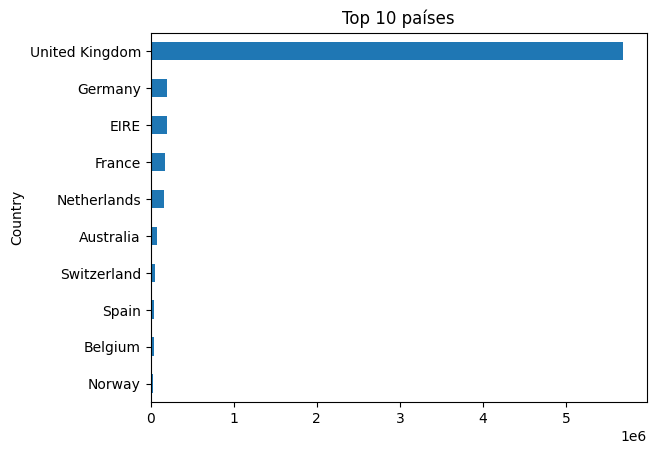

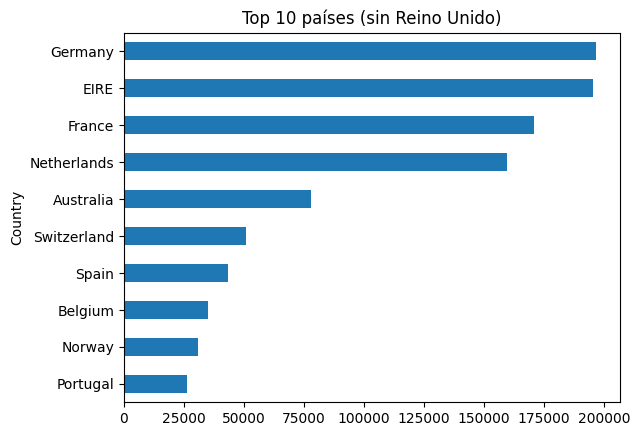

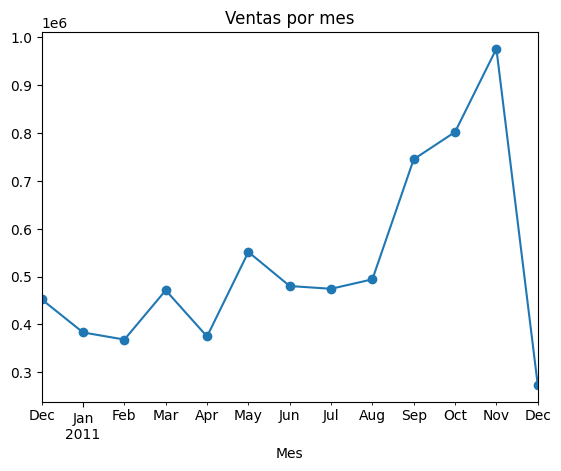

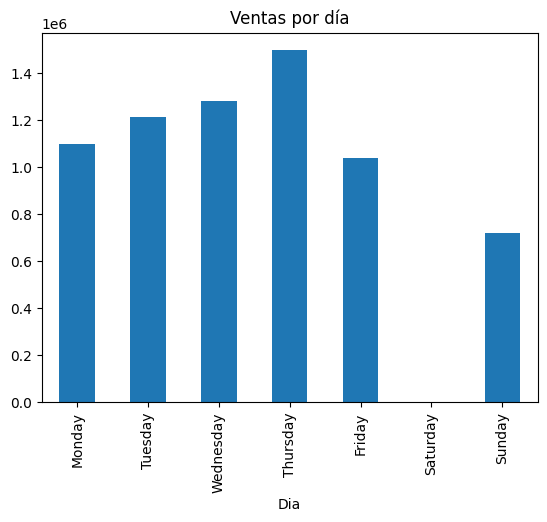

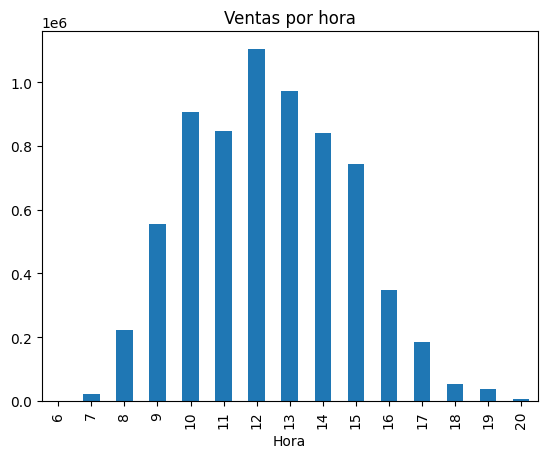

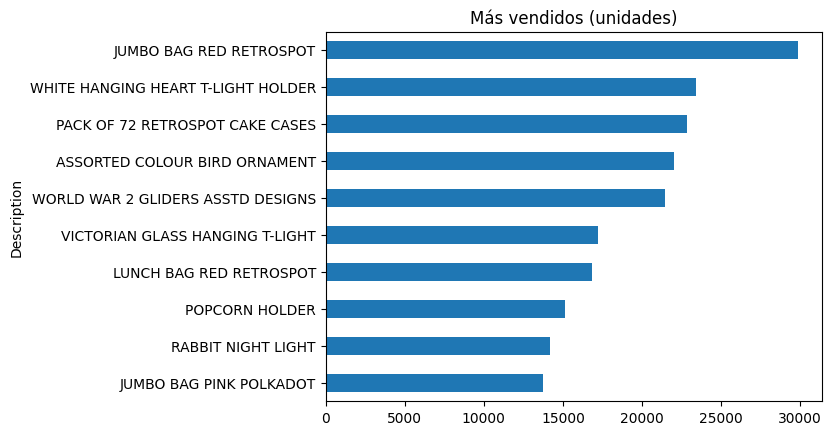

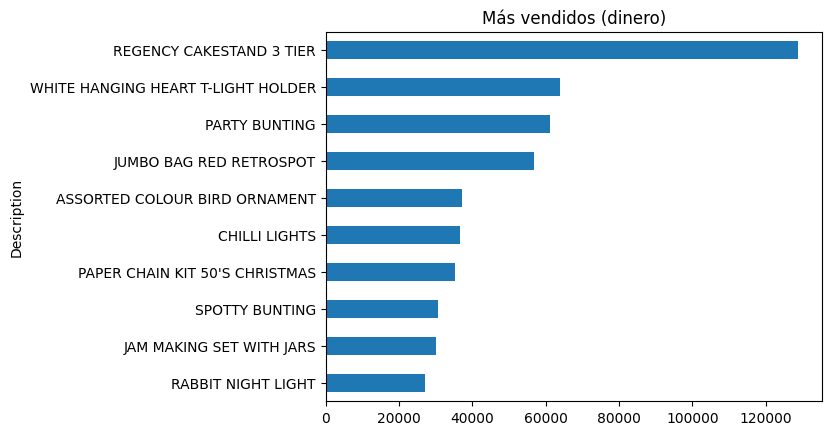


TOP 10 CLIENTES POR VENTAS
CustomerID
14646    154991.10
14911    124091.32
17511     73056.39
14156     67860.24
18102     66370.00
12415     65628.97
15311     56440.96
13089     54827.66
14088     48311.16
14096     47448.70
Name: Total, dtype: float64


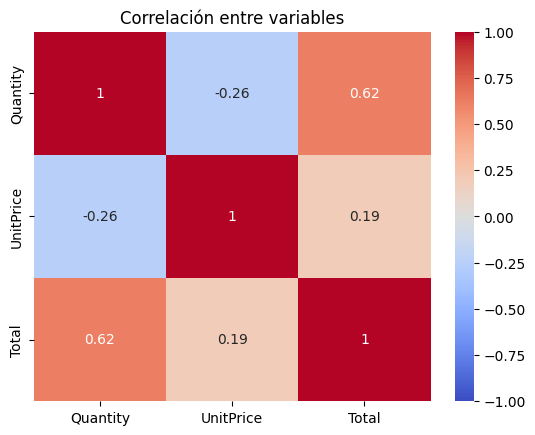

In [23]:
pipeline.eda()

## Reglas de asociación

In [24]:
reglas = PipelineEDA("online_retail_limpio.csv")

### 13. Transacciones (factura = canasta, producto = ítem)

In [25]:
reglas.preparar_transacciones()

Matriz lista: 17951 transacciones, 3795 productos.


### 14. Apriori

In [26]:
reglas.apriori(min_soporte=0.01, max_len=4)

C:\Proyecto-final-mineria2\.venv\lib\site-packages\mlxtend\frequent_patterns\fpcommon.py:161: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


Apriori completado en 126.5391s. Itemsets: 1021


,support,itemsets
0,0.013147,(10 COLOUR SPACEBOY PEN)
1,0.010417,(12 MESSAGE CARDS WITH ENVELOPES)
2,0.015208,(12 PENCIL SMALL TUBE WOODLAND)
3,0.016824,(12 PENCILS SMALL TUBE RED RETROSPOT)
4,0.015877,(12 PENCILS SMALL TUBE SKULL)
...,...,...
1016,0.012980,"(ROSES REGENCY TEACUP AND SAUCER, GREEN REGENC..."
1017,0.010696,"(LUNCH BAG CARS BLUE, LUNCH BAG BLACK SKULL., ..."
1018,0.010083,"(LUNCH BAG CARS BLUE, LUNCH BAG BLACK SKULL., ..."
1019,0.010194,"(LUNCH BAG SUKI DESIGN, LUNCH BAG BLACK SKULL...."


### 15. FP-Growth

In [27]:
reglas.fp_growth(min_soporte=0.01, max_len=4)

C:\Proyecto-final-mineria2\.venv\lib\site-packages\mlxtend\frequent_patterns\fpcommon.py:161: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


FP-Growth completado en 13.2503s. Itemsets: 1021


,support,itemsets
0,0.107738,(WHITE HANGING HEART T-LIGHT HOLDER)
1,0.017771,(KNITTED UNION FLAG HOT WATER BOTTLE)
2,0.017659,(RED WOOLLY HOTTIE WHITE HEART.)
3,0.016155,(SET 7 BABUSHKA NESTING BOXES)
4,0.013258,(CREAM CUPID HEARTS COAT HANGER)
...,...,...
1016,0.010306,"(LUNCH BAG APPLE DESIGN, LUNCH BAG VINTAGE DOILY)"
1017,0.012144,"(LOVE HOT WATER BOTTLE, HOT WATER BOTTLE KEEP ..."
1018,0.010027,"(HAND WARMER RED LOVE HEART, HAND WARMER UNION..."
1019,0.011253,"(HAND WARMER OWL DESIGN, HAND WARMER RED LOVE ..."


### 16. Eclat

In [28]:
reglas.eclat(min_soporte=0.01, max_len=4)

Eclat completado en 1.4603s. Itemsets: 1021


,support,itemsets
0,0.013147,(10 COLOUR SPACEBOY PEN)
1,0.010417,(12 MESSAGE CARDS WITH ENVELOPES)
2,0.015208,(12 PENCIL SMALL TUBE WOODLAND)
3,0.016824,(12 PENCILS SMALL TUBE RED RETROSPOT)
4,0.015877,(12 PENCILS SMALL TUBE SKULL)
...,...,...
1016,0.018885,(ZINC FOLKART SLEIGH BELLS)
1017,0.010417,(ZINC HERB GARDEN CONTAINER)
1018,0.026405,(ZINC METAL HEART DECORATION)
1019,0.012590,(ZINC T-LIGHT HOLDER STARS SMALL)


### 17. Comparación de los tres algoritmos

In [ ]:
reglas.comparar_algoritmos(min_soporte=0.01, max_len=4)

C:\Proyecto-final-mineria2\.venv\lib\site-packages\mlxtend\frequent_patterns\fpcommon.py:161: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


In [ ]:
reglas.graficar_tiempos()

### 18. Itemsets frecuentes

In [ ]:
reglas.graficar_itemsets("fp_growth", n=10, longitud_minima=2)

### 19. Reglas de asociación

In [ ]:
reglas.generar_reglas("fp_growth", min_confianza=0.5, min_lift=1.2)


In [ ]:
reglas.top_reglas("fp_growth", n=10, ordenar_por="lift")


In [ ]:
reglas.graficar_reglas("fp_growth")


In [ ]:
reglas.guardar_reglas("fp_growth", "reglas_asociacion.csv")

In [ ]:
reglas.guardar_reglas("fp_growth", "reglas_asociacion.csv")

In [ ]:
"""pipeline.convertir_tipos(
    columnas_int=["CustomerID"],
    columnas_fecha=["InvoiceDate"]
)

pipeline.filtrar_facturas_canceladas(
    obtener=False
)

pipeline.tratar_nulos(
    columnas=["Description"], # Se poseen suficientes valores para trabajar. 
    metodo="eliminar"        # Ademas, es una cantidad muy pequeña y es la variable objetivo
)

pipeline.eliminar_columnas(["CustomerID"]) # No es necesaria para el analisis
pipeline.analizar()"""